=====Before Preprocessing======
Total Number of dataste Text: (74682, 2)
Total duplicated Text: 4978
Total Missing values: Text         686
Sentiment      0
dtype: int64
=====After Preprocessing======
Total Number of dataset Text: (69700, 2)
Total Missing values: Text         0
Sentiment    0
dtype: int64
Total Duplicate  values: 0


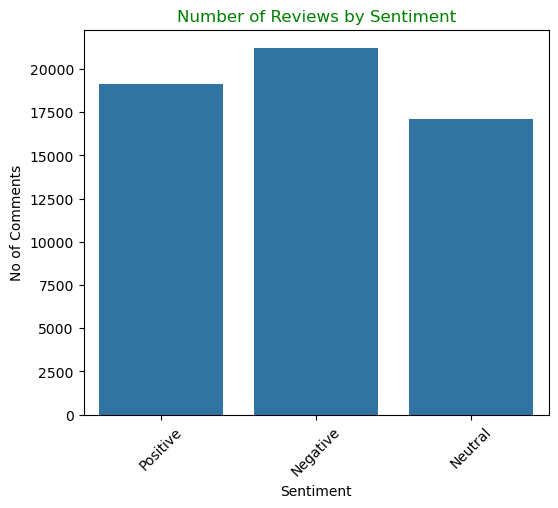

In [1]:
import pandas as pd 
import re
import matplotlib.pyplot as plt
import seaborn as sn
df=pd.read_csv("sent.csv",encoding="latin1")
df=df[['Text','Sentiment']]	
print("=====Before Preprocessing======")
print("Total Number of dataste Text:",df.shape)
print("Total duplicated Text:",df.duplicated().sum())
print("Total Missing values:",df.isnull().sum())
print("=====After Preprocessing======")
df=df.dropna()
df=df.drop_duplicates()
print("Total Number of dataset Text:",df.shape)
print("Total Missing values:",df.isnull().sum())
print("Total Duplicate  values:",df.duplicated().sum())
def remove_irreleva_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"[^a-z0-9\\s']", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text
df["Text"] = df["Text"].apply(remove_irreleva_text)
df["Text"] = df["Text"].astype(str).str.strip()
df["Sentiment"] = df["Sentiment"].astype(str).str.strip()
label_order = ["Positive", "Negative","Neutral"]
counts = df["Sentiment"].value_counts().reindex(label_order, fill_value=0)
plt.figure(figsize=(6, 5))
sn.barplot(x=counts.index, y=counts.values)
plt.xlabel("Sentiment")
plt.ylabel("No of Comments")
plt.title("Number of Reviews by Sentiment",color="green")
plt.xticks(rotation=45)
plt.show()

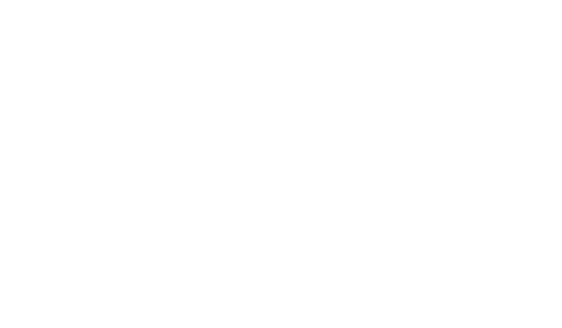

In [301]:
from wordcloud import WordCloud
text=" ".join(df)
data=WordCloud(width=500, height=600 ).generate(text)
plt.figure(figsize=(7, 4))
plt.plot(data=data,interpolation='bilinear')
plt.axis("off")
plt.show()

In [3]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vadar_analyzer = SentimentIntensityAnalyzer()
def vader_label(text):
    score = vadar_analyzer.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"
vader_scores = df["Text"].apply(vadar_analyzer.polarity_scores)
df["compound"] = vader_scores.apply(lambda x: x["compound"])
df["positive_score"] = vader_scores.apply(lambda x: x["pos"])
df["neutral_score"] = vader_scores.apply(lambda x: x["neu"])
df["negative_score"] = vader_scores.apply(lambda x: x["neg"])
df["prediction"] = df["Text"].apply(vader_label)
print(df[["Text", "Sentiment", 
          "prediction","compound", 
          "positive_score",
    "neutral_score", "negative_score"
]].head(12))

                                                 Text Sentiment prediction  \
0   im getting on borderlands and i will murder yo...  Positive   Negative   
1   i am coming to the borders and i will kill you...  Positive   Negative   
2   im getting on borderlands and i will kill you all  Positive   Negative   
3   im coming on borderlands and i will murder you...  Positive   Negative   
4   im getting on borderlands 2 and i will murder ...  Positive   Negative   
5   im getting into borderlands and i can murder y...  Positive   Negative   
6   so i spent a few hours making something for fu...  Positive   Positive   
7   so i spent a couple of hours doing something f...  Positive   Positive   
8   so i spent a few hours doing something for fun...  Positive   Positive   
9   so i spent a few hours making something for fu...  Positive   Positive   
10  2010 so i spent a few hours making something f...  Positive   Positive   
11                                                was  Positive 

In [7]:
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix
labels = ["Positive", "Negative", "Neutral"]
vader_accuracy = accuracy_score(df["Sentiment"], df["prediction"])
print(f"VADER accuracy on this sample: {vader_accuracy:.3f}")
print(classification_report(
    df["Sentiment"], df["prediction"],
    labels=labels, zero_division=0
))


VADER accuracy on this sample: 0.403
              precision    recall  f1-score   support

    Positive       0.40      0.68      0.50     19104
    Negative       0.46      0.57      0.51     21218
     Neutral       0.28      0.19      0.23     17103

   micro avg       0.40      0.49      0.44     57425
   macro avg       0.38      0.48      0.41     57425
weighted avg       0.39      0.49      0.42     57425



In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix
from sklearn.svm import SVC
X=df["Text"]
y=df["Sentiment"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2, random_state=42)
vectorize= TfidfVectorizer()
X_train=vectorize.fit_transform(X_train)
X_test=vectorize.transform(X_test)
model=RandomForestClassifier()
train=model.fit(X_train,y_train)
test=model.predict(X_test)
print(accuracy_score(test,y_test))
labels = ["Positive", "Negative", "Neutral"]
print(classification_report(test,y_test,labels=labels, zero_division=0))

0.9253228120516499
              precision    recall  f1-score   support

    Positive       0.95      0.90      0.92      4084
    Negative       0.95      0.91      0.93      4448
     Neutral       0.92      0.95      0.93      3223

   micro avg       0.94      0.92      0.93     11755
   macro avg       0.94      0.92      0.93     11755
weighted avg       0.94      0.92      0.93     11755



In [261]:
Compare = pd.DataFrame({
    "Text": X_test,
    "Original_Sentiment": y_test,
    "predicted_sentiment": test})
Compare["Result"] = (Compare["Original_Sentiment"] == Compare["predicted_sentiment"])
display(Compare.sort_values("Result"))

,Text,true_sentiment,predicted_sentiment,correct
26227,"(0, 2502)\t0.06703230000792998\n (0, 4083)\...",Irrelevant,Negative,False
23837,"(0, 1031)\t0.3298798014117523\n (0, 3803)\t...",Positive,Negative,False
42008,"(0, 8357)\t0.5339103262331103\n (0, 12343)\...",Negative,Positive,False
46082,"(0, 4385)\t0.34725804513280456\n (0, 11540)...",Positive,Negative,False
42080,"(0, 2312)\t0.22896422174063563\n (0, 4081)\...",Irrelevant,Neutral,False
...,...,...,...,...
12011,"(0, 4913)\t0.5194657433495011\n (0, 13554)\...",Neutral,Neutral,True
32343,"(0, 1923)\t0.14641687630438668\n (0, 2502)\...",Positive,Positive,True
53959,"(0, 2431)\t0.3931498340831289\n (0, 5041)\t...",Neutral,Neutral,True
12221,"(0, 1487)\t0.371259003162385\n (0, 4615)\t0...",Positive,Positive,True


In [275]:
Text = "I hate how this song is so short I wish it was longer"
print("Text:", Text)
print("VADER prediction:", vader_label(Text))
ll=vectorize.transform([Text])
print("Developed Model prediction:", model.predict(ll)[0])

Text: I hate how this song is so short I wish it was longer
VADER scores: {'neg': 0.209, 'neu': 0.623, 'pos': 0.168, 'compound': -0.1868}
VADER prediction: Negative
ML prediction: Positive
